# Telco Customer Churn

In [90]:
# Imports

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import brier_score_loss

from sklearn.calibration import calibration_curve, CalibratedClassifierCV

# - LogisticRegression: Cria um modelo de regressão logística para classificação, estimando a probabilidade de uma observação pertencer a uma classe.

# - StratifiedKFold: Divide os dados em k partes, preservando aproximadamente a proporção das classes em cada parte.

# - cross_val_score: Avalia o modelo por validação cruzada e retorna a métrica de desempenho obtida em cada divisão.

# - train_test_split: Divide os dados em conjuntos de treino e teste para treinar e avaliar o modelo em observações separadas.

# - Pipeline: Encadeia etapas de processamento e modelagem, executando-as sequencialmente e ajudando a evitar vazamento de dados (data leakage).

# - OneHotEncoder: Transforma variáveis categóricas em colunas binárias, representando cada categoria com um indicador.

# - StandardScaler: Padroniza variáveis numéricas para terem média 0 e desvio-padrão 1, calculados nos dados usados no ajuste.

# - ColumnTransformer: Aplica transformações diferentes a grupos específicos de colunas, como padronizar variáveis numéricas e codificar categóricas.

# - SimpleImputer: Preenche valores ausentes usando uma estratégia definida, como média, mediana, valor mais frequente ou uma constante.

In [91]:
# Carregar dados

# dados = pd.read_csv(r"data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Podemos usar a seguinte abordagem para rodar em qualquer local
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = RAIZ / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
dados = pd.read_csv(data_path)

In [92]:
dados.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [93]:
# Coluna TotalCharges deve ser convertida para numeric
dados['TotalCharges'] = pd.to_numeric(dados['TotalCharges'], errors="coerce")

In [94]:
numericos = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
categoricos = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod']
target = ['Churn']

In [95]:
dados.isna().sum().sort_values(ascending=False)

TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
Contract             0
StreamingMovies      0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
Churn                0
dtype: int64

In [96]:
dados.loc[dados["TotalCharges"].isna(), ["tenure", "MonthlyCharges"]]

# Aqui vamos imputar 0 em totalCharges pois tenure (meses na empresa) 0 indica que nao ocorreu cobrança

dados.loc[dados["TotalCharges"].isna() & (dados["tenure"] == 0), "TotalCharges"] = 0

In [100]:
df_contract

,Contract,taxa_churn
0,Month-to-month,42.709677
1,One year,11.269518
2,Two year,2.831858


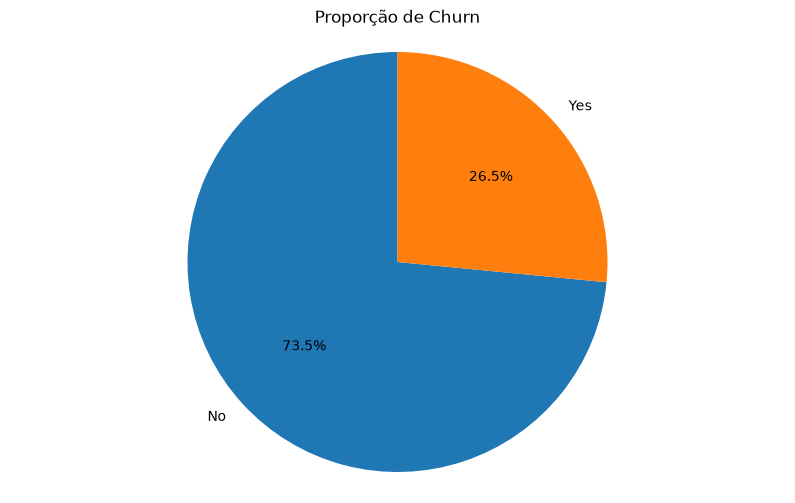

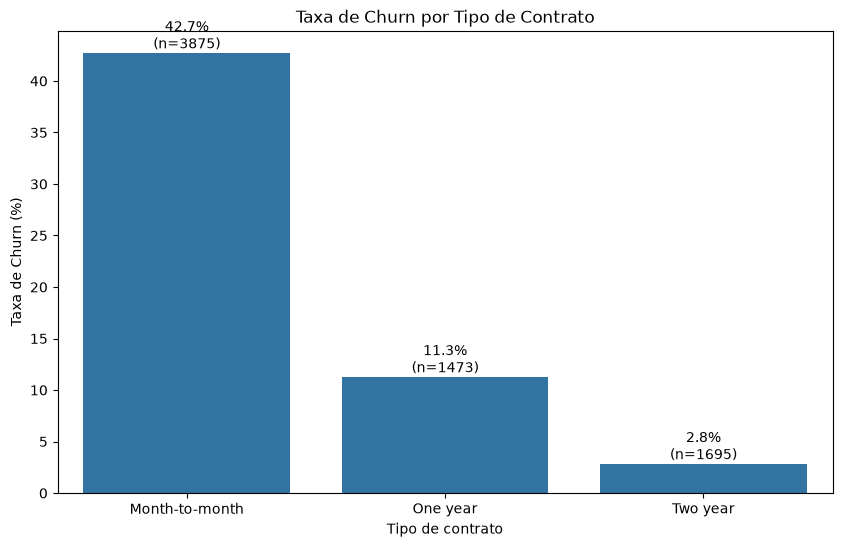

In [103]:
# Taxa de Churn Geral e por Contract

df_churn = dados['Churn'].value_counts(normalize=True) * 100

df_contract = dados.groupby("Contract").agg(
    total=("Churn", "count"),
    churn=("Churn", lambda x: (x == "Yes").sum())
)

df_contract["taxa_churn"] = (
    df_contract["churn"] / df_contract["total"] * 100
)


fig, ax = plt.subplots(figsize = (10,6))
plt.pie(df_churn, labels = df_churn.index, autopct='%1.1f%%', startangle=90)
ax.set_title("Proporção de Churn")
ax.axis('equal')



fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=df_contract,
    x="Contract",
    y="taxa_churn",
    ax=ax
)

rotulos = [
    f"{taxa:.1f}%\n(n={n})"
    for taxa, n in zip(df_contract["taxa_churn"], df_contract["total"])
]
ax.bar_label(ax.containers[0], labels=rotulos)

ax.set_title("Taxa de Churn por Tipo de Contrato")
ax.set_xlabel("Tipo de contrato")
ax.set_ylabel("Taxa de Churn (%)")



plt.show()

In [ ]:
# Vamos usar One-Hot Encoder para as categóricas e StandardScaler para as numericas (x-media/sd) e Imputer para os valores faltantes.
# Devemos fazer isso somente nos dados de TREINO para não haver data_leakage (padronizarmos com os valores provenientes de dados de teste)

pre = ColumnTransformer([
    ("numericos", Pipeline([
        ("imputer", SimpleImputer(strategy="median")), # como ja tratamos anteriormente, fica como guardrail
        ("scaler", StandardScaler()) # padroniza
    ]), numericos), # nome > pipe > dados
    ("categoricos", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")), # se faltar dados nas categorias, troca pelo valor mais frequente
        ("onehot", OneHotEncoder(handle_unknown="ignore")) # se no teste aparecer algum valor que não existia no treino ele ignora
    ]), categoricos) # nome > pipe > dados
])

modelo_lr = Pipeline([
    ("pre", pre), ("classifier", LogisticRegression(max_iter = 10_000)) # ajusta os dados e depois passa para o modelo
])

# Até aqui apenas definimos o roteiro, agora precisamos separar os dados que irão entrar na história

X = dados[numericos + categoricos] # sem a target aqui
y = (dados['Churn'] == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1) # Separa treino e teste na prop 80/20, stratify=y mantém as proporcoes de y no treino e teste

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)

scores = cross_val_score(modelo_lr, X_train, y_train, cv = cv, scoring= "roc_auc") # avaliamos cópias internas com X_train e y_train usando Cross Validation (imagem abaixo)

print(scores.mean(), scores.std())

0.8475677973297919 0.016048708408888546


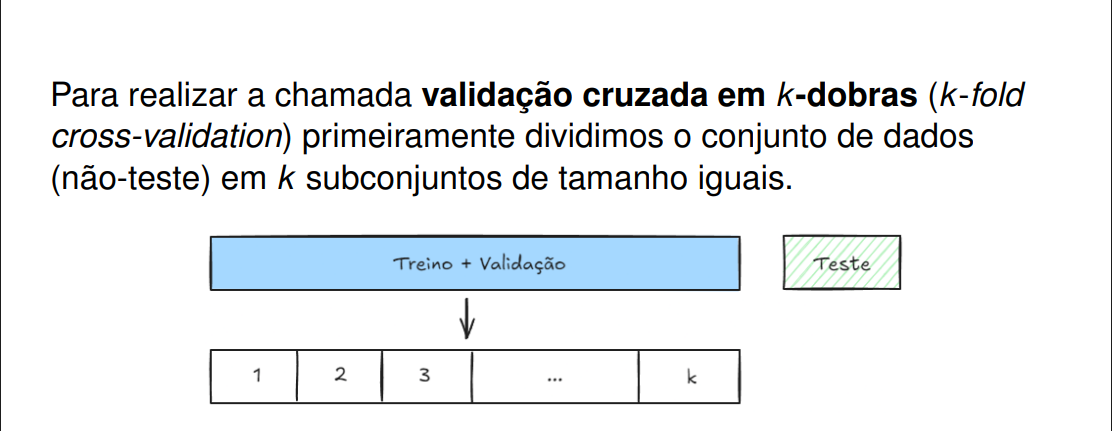

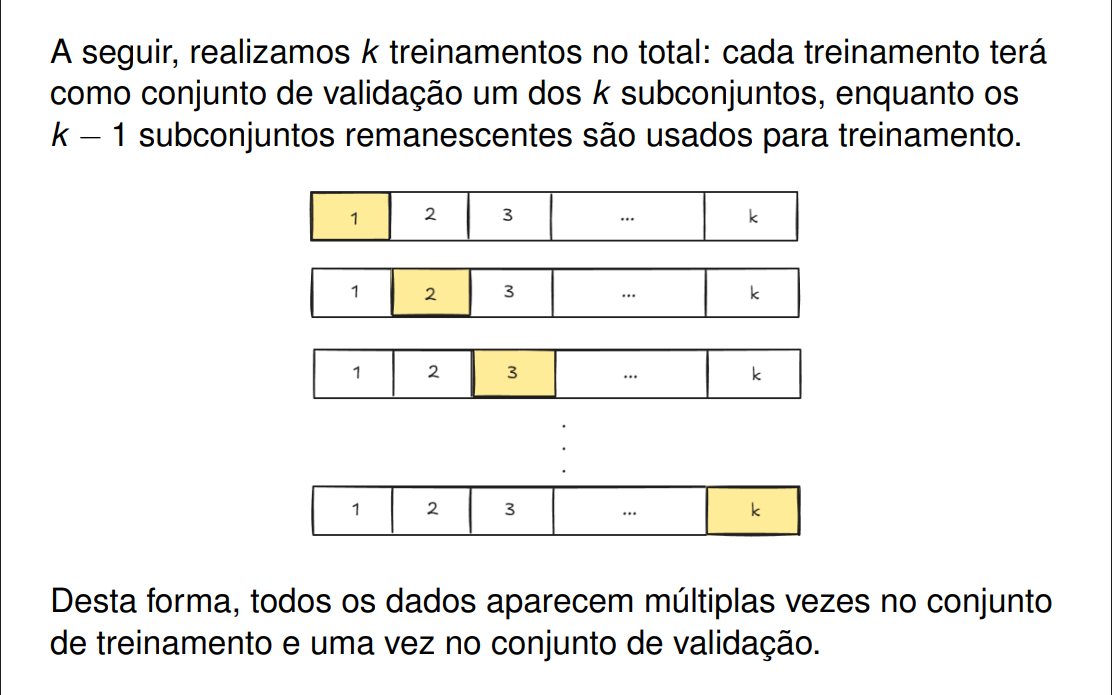

In [43]:
# Vamos usar One-Hot Encoder para as categóricas e StandardScaler para as numericas (x-media/sd) e Imputer para os valores faltantes.
# Devemos fazer isso somente nos dados de TREINO para não haver data_leakage (padronizarmos com os valores provenientes de dados de teste)

pre = ColumnTransformer([
    ("numericos", Pipeline([
        ("imputer", SimpleImputer(strategy="median")), # nos dados faltantes de 'TotalCharges'
        ("scaler", StandardScaler()) # padroniza
    ]), numericos), # nome > pipe > dados
    ("categoricos", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")), # se faltar dados nas categorias, troca pelo valor mais frequente
        ("onehot", OneHotEncoder(handle_unknown="ignore")) # se no teste aparecer algum valor que não existia no treino ele ignora
    ]), categoricos) # nome > pipe > dados
])

modelo_rf = Pipeline([
    ("pre", pre),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=1)),
])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)

scores = cross_val_score(modelo_rf, X_train, y_train, cv = cv, scoring= "roc_auc") # avaliamos cópias internas treinado com X_train e y_train usando Cross Validation (imagem abaixo)

print(scores.mean(), scores.std())

0.8266398134403357 0.017212530167139566


Note que o AUC da Regressão Logistica é maior que do Random Forest (0.848 vs 0.827), nesse caso, vamos ficar com o modelo de Regressão Logística.

In [44]:
modelo_lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['SeniorCitizen','tenure','MonthlyCharges',...,'Contract', 'PaperlessBilling','PaymentMethod']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericos', ...), ('categoricos', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

# Calibração no teste

In [57]:
proba = modelo_lr.predict_proba(X_test)[:,1] # valores preditos

In [60]:
modelo_lr.classes_

array([0, 1])

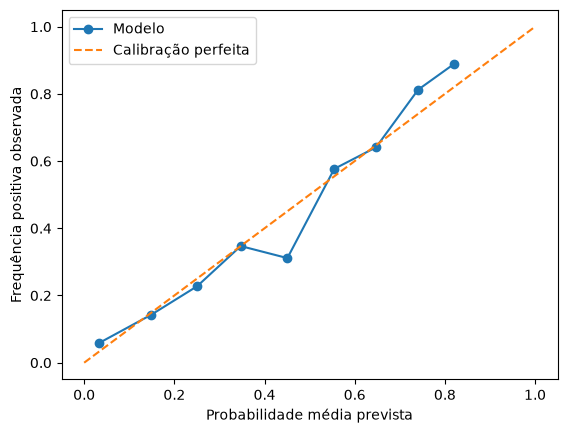

In [69]:
prob_true, prob_pred = calibration_curve(
    y_test,
    proba,
    n_bins=10,
    strategy="uniform"
)

plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
plt.legend()
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência positiva observada")
plt.show()

Quanto mais próxima da diagonal, melhor calibrada estão as probabilidades. Isso é importante pois mais que classificar corretamente os clientes, as probabilidades estimadas devem ser confiáveis

In [71]:
brier = brier_score_loss(y_test, proba)

print(f"Brier Score: {brier:.4f}")

Brier Score: 0.1380


Quanto menor o score de Brier, melhor. O score compara a probabilidade prevista com o resultado observado penalizando as previsões erradas com maior confiança. A diferença para a acurácia é que a acurácia avalia a classificação final enquanto o Brier avalia as probabilidades previstas.

In [74]:
modelo_cal = CalibratedClassifierCV(modelo_lr, method="sigmoid", cv=5)
modelo_cal.fit(X_train, y_train)
proba_cal = modelo_cal.predict_proba(X_test)[:, 1]
print(brier_score_loss(y_test, proba_cal))

0.1380059175626457


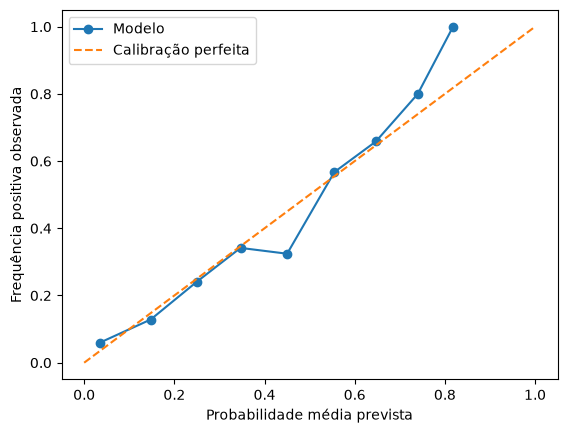

In [76]:
prob_true, prob_pred_cal = calibration_curve(
    y_test,
    proba_cal,
    n_bins=10,
    strategy="uniform"
)

plt.plot(prob_pred_cal, prob_true, marker="o", label="Modelo")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
plt.legend()
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência positiva observada")
plt.show()